# Credit Card Case Study: Customer Spend & Repayment Analysis
**Author:** Amal Shesnij

## Setup: load the 3 sheets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)

file = 'Credit Card Data.xlsx'
customers = pd.read_excel(file, sheet_name='Customer Acqusition')
spend = pd.read_excel(file, sheet_name='Spend')
repay = pd.read_excel(file, sheet_name='Repayment')

for name, df in [('customers', customers), ('spend', spend), ('repay', repay)]:
    print(f'{name:10} {df.shape}')

customers.head()

customers  (100, 8)
spend      (1500, 5)
repay      (1500, 4)


,No,Customer,Age,City,Product,Limit,Company,Segment
0,1,A1,34.01,BANGALORE,Gold,500000,C1,Self Employed
1,2,A2,50.50,CALCUTTA,Silver,100000,C2,Salaried_MNC
2,3,A3,35.86,COCHIN,Platimum,10000,C3,Salaried_Pvt
3,4,A4,27.36,BOMBAY,Platimum,10001,C4,Govt
4,5,A5,22.02,BANGALORE,Platimum,10002,C5,Normal Salary


## Q1. Data cleaning

In [2]:
# Fix the product spelling
customers['Product'] = customers['Product'].replace('Platimum', 'Platinum')

# 1a. Age under 18 -> replace with the mean age
mean_age = customers['Age'].mean()
print(f'1a. Customers under 18: {(customers["Age"] < 18).sum()}  (mean age = {mean_age:.2f})')
customers.loc[customers['Age'] < 18, 'Age'] = mean_age

# Attach each customer's limit to their spend and repayment rows
spend = spend.merge(customers[['Customer', 'Limit']], on='Customer', how='left')
repay = repay.merge(customers[['Customer', 'Limit']], on='Customer', how='left')

# 1b. Spend above the limit -> 50% of the limit
over = spend['Amount'] > spend['Limit']
print(f'1b. Spend rows above limit: {over.sum()}')
spend.loc[over, 'Amount'] = 0.5 * spend.loc[over, 'Limit']

# 1c. Repayment above the limit -> the limit
over = repay['Amount'] > repay['Limit']
print(f'1c. Repayment rows above limit: {over.sum()}')
repay.loc[over, 'Amount'] = repay.loc[over, 'Limit']

1a. Customers under 18: 25  (mean age = 37.46)
1b. Spend rows above limit: 591
1c. Repayment rows above limit: 604


**Conclusion (Q1):** 25 customers under 18 had their age replaced with the mean age (37.46). 591 spend transactions above the card limit were set to 50% of the limit, and 604 repayments above the limit were capped at the limit. "Platimum" was corrected to "Platinum".

## Q2. Summaries

### 2a–d. Customers, categories, average monthly spend and repayment

In [3]:
print('2a. Distinct customers :', customers['Customer'].nunique())
print('2b. Distinct categories:', spend['Type'].nunique())

spend['Month_P'] = spend['Month'].dt.to_period('M')
repay['Month_P'] = repay['Month'].dt.to_period('M')

monthly = pd.DataFrame({
    'Spend': spend.groupby('Month_P')['Amount'].sum(),
    'Repayment': repay.groupby('Month_P')['Amount'].sum(),
}).fillna(0)

print(f"\n2c. Average monthly spend    : {monthly['Spend'].mean():,.2f}")
print(f"2d. Average monthly repayment: {monthly['Repayment'].mean():,.2f}")

2a. Distinct customers : 100
2b. Distinct categories: 15

2c. Average monthly spend    : 7,624,286.60
2d. Average monthly repayment: 8,280,252.03


### 2e. Monthly profit for the bank (2.9% interest)

In [4]:
monthly['Net'] = monthly['Repayment'] - monthly['Spend']
monthly['Interest (2.9%)'] = np.where(monthly['Net'] > 0, monthly['Net'] * 0.029, 0)

print(f"2e. Total profit for the bank: {monthly['Interest (2.9%)'].sum():,.2f}")
print(f"    Months with positive profit: {(monthly['Net'] > 0).sum()} of {len(monthly)}")
monthly

2e. Total profit for the bank: 929,363.00
    Months with positive profit: 21 of 30


,Spend,Repayment,Net,Interest (2.9%)
Month_P,,,,
2004-01,"46,459,874.72","45,161,919.58","-1,297,955.14",0.00
2004-02,"4,134,085.15","4,738,437.51","604,352.36","17,526.22"
2004-03,"1,254,961.60","2,811,495.88","1,556,534.28","45,139.49"
2004-04,"3,833,059.98","4,226,593.85","393,533.87","11,412.48"
2004-05,"2,372,873.66","3,864,227.20","1,491,353.54","43,249.25"
2004-09,"1,882,803.99","2,024,091.45","141,287.46","4,097.34"
2004-11,"1,967,215.14","2,276,063.01","308,847.87","8,956.59"
2005-01,"4,563,799.79","5,224,097.16","660,297.38","19,148.62"
2005-02,"28,239,796.52","24,180,369.91","-4,059,426.61",0.00


### 2f–h. Top product types, top city, spend by age group

In [5]:
# Attach city and age to each spend row
spend = spend.merge(customers[['Customer', 'City', 'Age', 'Product']], on='Customer', how='left')

print('2f. Top 5 product types (by amount spent):')
print(spend.groupby('Type')['Amount'].sum().nlargest(5))

city = spend.groupby('City')['Amount'].sum().sort_values(ascending=False)
print(f'\n2g. City with maximum spend: {city.index[0]} ({city.iloc[0]:,.2f})')

bins = [18, 30, 40, 50, 60, 80]
labels = ['18-29', '30-39', '40-49', '50-59', '60+']
spend['Age_Group'] = pd.cut(spend['Age'], bins=bins, labels=labels, right=False)
print('\n2h. Spend by age group:')
print(spend.groupby('Age_Group', observed=True)['Amount'].sum())

2f. Top 5 product types (by amount spent):
Type
PETRO          31,067,654.25
CAMERA         28,648,003.90
FOOD           24,404,427.66
AIR TICKET     23,780,680.62
TRAIN TICKET   19,610,407.82
Name: Amount, dtype: float64

2g. City with maximum spend: COCHIN (48,574,542.86)

2h. Spend by age group:
Age_Group
18-29    26,332,068.11
30-39   109,181,549.47
40-49    31,252,879.98
50-59    30,373,566.41
60+      31,588,534.01
Name: Amount, dtype: float64


### 2i. Top 10 customers by repayment

In [6]:
top10 = repay.groupby('Customer')['Amount'].sum().nlargest(10)
print('2i. Top 10 customers by repayment:')
top10

2i. Top 10 customers by repayment:


Customer
A61   9,672,793.52
A60   9,168,149.95
A42   8,928,473.48
A13   8,496,395.78
A38   8,205,336.50
A43   7,976,031.15
A40   7,671,795.78
A14   7,655,254.89
A44   7,637,481.58
A26   7,472,188.59
Name: Amount, dtype: float64

**Conclusion (Q2):**
- 100 customers spend across 15 categories. Average monthly spend is 7.62M and average monthly repayment is 8.28M (over the 30 months that have transactions).
- At 2.9% monthly interest on positive net repayment, the bank earns **929,363** in total, from 21 of 30 months. In real banking, interest is earned on unpaid balances, so this is a simplified profit definition from the case brief.
- Top spend categories: Petrol, Camera, Food, Air tickets and Train tickets. **Cochin** has the highest total spend.
- The 30–39 age group shows the highest spend, but this is largely because the 25 under-18 customers were all replaced with the mean age (37.46), which places them in that band. The age-group result should be read with this in mind.
- Customer A61 has the highest total repayment (9.67M).

## Q3. City-wise yearly spend by product

Year               2004                                    2005               \
Product            Gold     Platinum       Silver          Gold     Platinum   
City                                                                           
BANGALORE  9,870,697.48 1,045,045.91 1,215,574.95 14,914,471.02   885,722.61   
BOMBAY     6,221,750.00   946,976.34   518,676.34  9,533,804.39   836,008.47   
CALCUTTA   8,643,979.18 2,178,863.27   597,488.36 11,691,980.02 4,822,990.05   
CHENNAI    1,415,072.88 2,944,114.92   308,774.69  3,013,080.93 5,243,051.17   
COCHIN     9,730,434.55 2,974,235.36   789,194.95 11,025,312.81 4,151,462.73   
DELHI      3,467,979.09   338,842.13   804,097.08  2,508,487.43   443,619.82   
PATNA      1,915,473.34   816,637.27   844,829.53  2,187,692.09 2,534,969.17   
TRIVANDRUM 2,272,699.66 1,770,528.16   272,908.78  1,984,570.77 3,401,178.64   

Year                           2006                            
Product        Silver          Gold     Platinum       Silver  
City                                                           
BANGALORE  909,077.89 13,121,349.45   709,694.49 1,650,718.66  
BOMBAY     572,757.22 10,196,028.75 1,022,213.94   849,474.78  
CALCUTTA   343,259.51  9,571,088.34 2,456,411.61   876,154.14  
CHENNAI    428,758.51  3,057,965.84 6,066,895.56   313,388.10  
COCHIN     643,789.22 12,628,278.51 5,530,968.85 1,100,865.89  
DELHI      493,446.15  3,535,699.84   133,365.05   760,770.64  
PATNA      949,455.26  2,424,509.41   745,381.45   697,258.92  
TRIVANDRUM 372,614.29  2,827,396.99 2,122,721.65   533,562.71

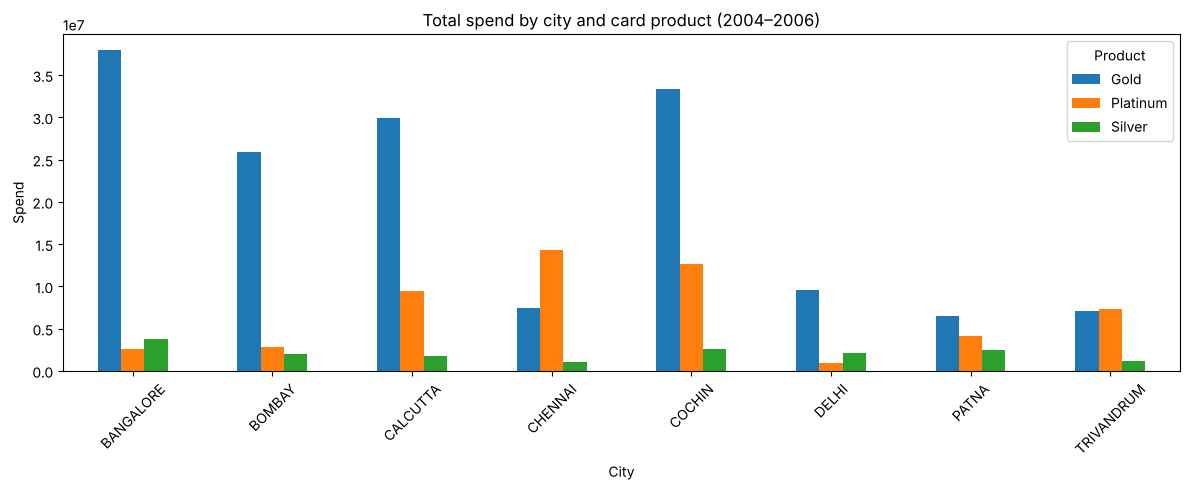

In [7]:
spend['Year'] = spend['Month'].dt.year

city_product = pd.pivot_table(spend, index='City', columns=['Year', 'Product'],
                              values='Amount', aggfunc='sum', fill_value=0)
display(city_product)

city_product.T.groupby(level='Product').sum().T.plot(kind='bar', figsize=(12, 5))
plt.title('Total spend by city and card product (2004–2006)')
plt.ylabel('Spend'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Conclusion (Q3):** Gold card holders account for most spending in almost every city, led by Bangalore, Cochin and Calcutta. Chennai is the exception, where Platinum card holders spend the most. Silver card spend is low in all cities, so Gold customers in the top cities are the bank's most valuable segment.

## Q4. Spend trends

### 4a. Monthly spend by city

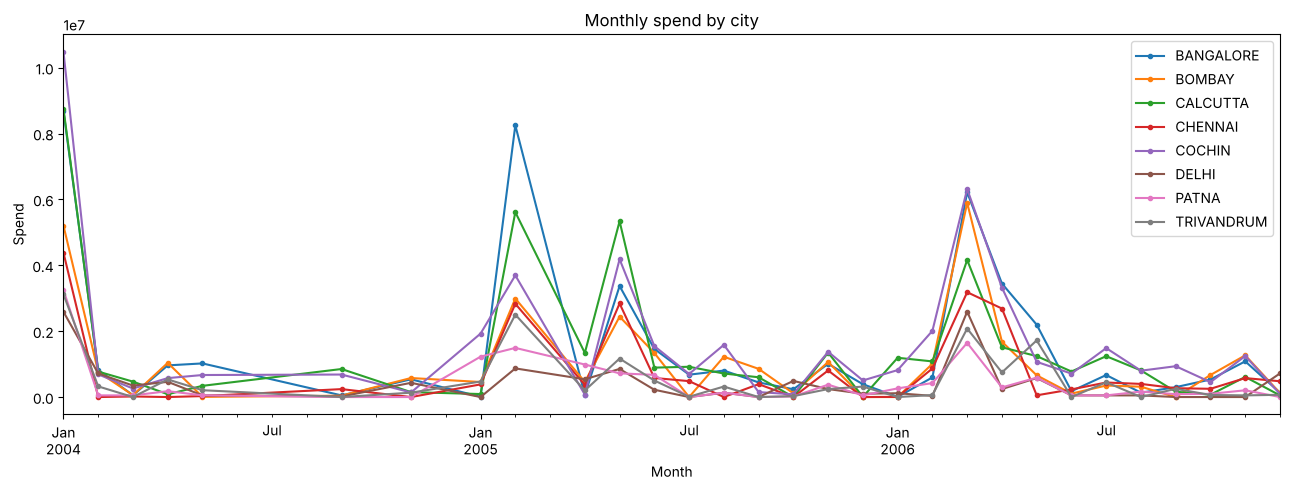

In [8]:
city_month = spend.pivot_table(index='Month_P', columns='City', values='Amount', aggfunc='sum', fill_value=0)
city_month.plot(figsize=(13, 5), marker='o', markersize=3)
plt.title('Monthly spend by city'); plt.ylabel('Spend'); plt.xlabel('Month')
plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

### 4b. Yearly spend on air tickets

Year
2004   5,565,998.88
2005   9,551,943.61
2006   8,662,738.13
Name: Amount, dtype: float64


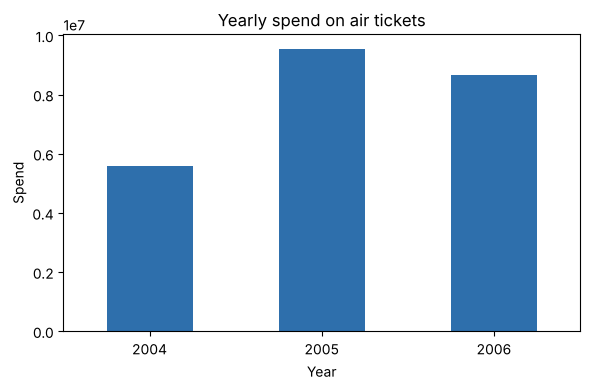

In [9]:
air = spend[spend['Type'] == 'AIR TICKET'].groupby('Year')['Amount'].sum()
print(air)
air.plot(kind='bar', color='#2E6FAC', figsize=(6, 4))
plt.title('Yearly spend on air tickets'); plt.ylabel('Spend'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### 4c. Monthly spend by category (seasonality)

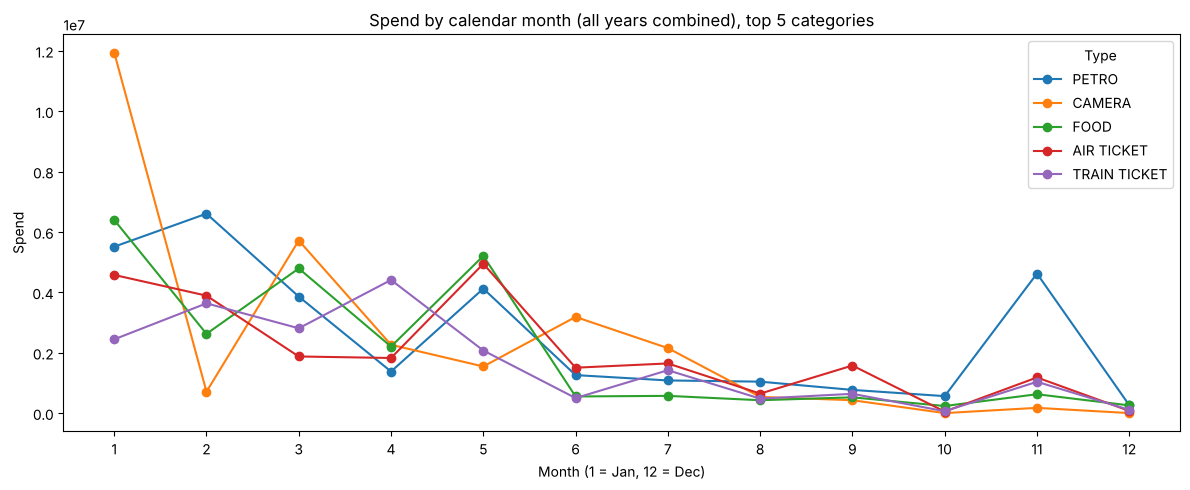

In [10]:
spend['Month_No'] = spend['Month'].dt.month
season = spend.pivot_table(index='Month_No', columns='Type', values='Amount', aggfunc='sum', fill_value=0)
season[['PETRO', 'CAMERA', 'FOOD', 'AIR TICKET', 'TRAIN TICKET']].plot(figsize=(12, 5), marker='o')
plt.title('Spend by calendar month (all years combined), top 5 categories')
plt.xlabel('Month (1 = Jan, 12 = Dec)'); plt.ylabel('Spend'); plt.xticks(range(1, 13))
plt.tight_layout(); plt.show()

**Conclusion (Q4):**
- Spend is concentrated in the first half of the year: January to May is clearly higher than June to December across all top categories, with camera spending peaking in January.
- Air ticket spend rose from 5.57M in 2004 to 9.55M in 2005, then eased to 8.66M in 2006.
- Petrol is the exception, with a spike in November.
- Note: several months have no transactions in the data, so part of this pattern may come from uneven data coverage rather than true seasonality.

## Q5. Top 10 customers function

In [11]:
# Attach city and product to each repayment row
repay = repay.merge(customers[['Customer', 'City', 'Product']], on='Customer', how='left')
repay['Year'] = repay['Month'].dt.year

def top10_customers(product, period):
    """Top 10 customers by repayment in each city, for one card product,
    grouped by year or by month."""
    period_col = {'yearly': 'Year', 'monthly': 'Month_P'}[period.lower()]

    data = repay[repay['Product'] == product]
    totals = (data.groupby(['City', period_col, 'Customer'])['Amount'].sum()
                  .reset_index()
                  .sort_values(['City', period_col, 'Amount'], ascending=[True, True, False]))
    return totals.groupby(['City', period_col]).head(10).reset_index(drop=True)

top10_customers('Gold', 'yearly')

,City,Year,Customer,Amount
0,BANGALORE,2004,A14,"2,471,341.69"
1,BANGALORE,2004,A13,"2,196,412.20"
2,BANGALORE,2004,A43,"2,083,654.76"
3,BANGALORE,2004,A1,"2,066,124.75"
4,BANGALORE,2004,A30,"1,493,288.84"
...,...,...,...,...
83,PATNA,2006,A26,"2,762,535.23"
84,PATNA,2006,A66,"268,456.73"
85,TRIVANDRUM,2004,A28,"1,710,922.35"
86,TRIVANDRUM,2005,A28,"2,265,215.14"


### Testing the function with different inputs

In [12]:
top10_customers('Platinum', 'monthly').head(15)

,City,Month_P,Customer,Amount
0,BANGALORE,2004-01,A37,"484,737.39"
1,BANGALORE,2004-01,A52,"214,150.46"
2,BANGALORE,2004-01,A5,"60,012.00"
3,BANGALORE,2004-01,A19,"40,000.00"
4,BANGALORE,2004-05,A37,"178,235.49"
5,BANGALORE,2004-05,A5,"10,002.00"
6,BANGALORE,2004-09,A37,"61,203.25"
7,BANGALORE,2004-09,A19,"10,000.00"
8,BANGALORE,2004-11,A37,"100,003.00"
9,BANGALORE,2005-01,A19,"10,000.00"


**Conclusion (Q5):** The function `top10_customers(product, period)` returns the top 10 customers in each city by repayment, for a chosen card product (Gold, Silver or Platinum) and time period ('yearly' or 'monthly'). Where a city has fewer than 10 customers for a product in a given period, all of them are shown.

## Key Findings
1. **Data quality:** 25 customers were under 18, 591 spend rows and 604 repayment rows exceeded the card limit, and were corrected using the case rules. Such high rates suggest the data is simulated.
2. **Scale:** 100 customers across 15 spend categories; average monthly spend 7.62M and repayment 8.28M.
3. **Bank profit:** 929,363 in total at 2.9% monthly interest on positive net repayment (21 of 30 months profitable).
4. **Top categories:** Petrol, Camera, Food, Air tickets and Train tickets.
5. **Top city:** Cochin has the highest spend; Gold card holders dominate spending in most cities, while Platinum leads in Chennai.
6. **Seasonality:** spend is highest from January to May, with a petrol spike in November, partly influenced by uneven monthly data coverage.
7. **Top customer:** A61 has the highest total repayment (9.67M).

## Assumptions
- The Excel workbook was used as the official data source (the CSV files contain different values).
- "Platimum" was corrected to "Platinum".
- Averages are calculated over the 30 months that have transactions.
- The age-group result is affected by replacing under-18 ages with the mean age (37.46).